# 02 · Limpieza y homologación

Se ejecuta `src/ML_C/01_limpieza.py`, que deja **una sola tabla limpia** de producción municipal y la **lista de productos** a modelar. Este notebook muestra las decisiones y comprueba los conteos de la propuesta: 57 → 44 → 22 + 22.

In [1]:
import os, sys
from pathlib import Path
from importlib import import_module

ROOT = Path.cwd().resolve()
while not (ROOT / "config/ML_C/parametros.yaml").exists():
    ROOT = ROOT.parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src/ML_C"))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from common import CFG, RAW, CLEAN, RES
from graficos import estilo, COLORES
estilo(); pd.set_option("display.max_columns", 30, "display.width", 160)

In [2]:
limpieza = import_module("01_limpieza")
limpieza.HARMONIZAR

{'Aguacate Hass': 'Aguacate', 'Limón': 'Cítricos', 'Mandarina': 'Cítricos', 'Naranja': 'Cítricos'}

In [3]:
limpieza.main()

parquet omitido: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - `Import pyarrow` failed. pyarrow is required for parquet support. Use pip or conda to install the pyarrow package.
 - `Import fastparquet` failed. fastparquet is required for parquet support. Use pip or conda to install the fastparquet package.
filas crudas 15282 | duplicados exactos 18 | filas limpias 15019
cultivos originales 61 -> armonizados 57
estado: {'detallado': 22, 'simplificado': 22, 'excluido': 13} | municipios: 42 | años 2000 2023


## Decisiones de armonización (tabla para Carlos)

In [4]:
pd.read_csv(RES / "decisiones_armonizacion.csv")

,decision,producto_o_campo,accion,motivo
0,Separador de miles en el CSV,Todas,"Se limpian comas antes de convertir (año, id m...","Evita años como '2,000' y códigos DANE mal for..."
1,Código DANE,Id_municipio,Se convierte a texto de 5 dígitos (zfill).,Coincide con DIVIPOLA para los 42 municipios.
2,Filas duplicadas exactas,"Brevo, Té",Se eliminan 18 filas idénticas (antes de armon...,Duplicado de captura; no aporta información.
3,Escritura de familia,Raíces y tubérculos,'Raíces y tubérculos' -> 'Raíces y Tubérculos'.,Dos escrituras de la misma familia.
4,Cartuchos,Cartuchos,Se reclasifica de Raíces y Tubérculos a Flores.,Es una flor; queda excluido por no tener produ...
5,Cambio de desagregación,Aguacate Hass,Se suma a 'Aguacate'.,Separado desde 2020; se suma a 'Aguacate' para...
6,Cambio de desagregación,Limón,Se suma a 'Cítricos'.,Desagregado desde 2021 (antes dentro de 'Cítri...
7,Cambio de desagregación,Mandarina,Se suma a 'Cítricos'.,Desagregado desde 2021 (antes dentro de 'Cítri...
8,Cambio de desagregación,Naranja,Se suma a 'Cítricos'.,Desagregado desde 2021 (antes dentro de 'Cítri...
9,Rendimiento,Todos,Se recalcula como producción / ha cosechadas t...,El rendimiento original no es sumable.


## Verificación de la tabla limpia

In [5]:
d = pd.read_csv(CLEAN / "produccion_valle_clean.csv", dtype={"cod_dane": str})
lp = pd.read_csv(CLEAN / "lista_productos.csv")
checks = {
    "42 municipios": d.cod_dane.nunique() == 42,
    "código DANE de 5 dígitos": d.cod_dane.str.len().eq(5).all(),
    "sin duplicados (año, municipio, producto)": not d.duplicated(["anio", "cod_dane", "producto"]).any(),
    "57 productos armonizados": d.producto.nunique() == 57,
    "22 / 22 / 13": lp.estado.value_counts().to_dict() == {"detallado": 22, "simplificado": 22, "excluido": 13},
}
pd.Series(checks).to_frame("cumple")

,cumple
42 municipios,True
código DANE de 5 dígitos,True
"sin duplicados (año, municipio, producto)",True
57 productos armonizados,True
22 / 22 / 13,True


In [6]:
lp[["producto", "familia", "estado", "ranking_toneladas", "produccion_t_2019_2023", "n_municipios_2019_2023"]].head(25)

,producto,familia,estado,ranking_toneladas,produccion_t_2019_2023,n_municipios_2019_2023
0,Caña de azúcar,Cultivos Tropicales Tradicionales,detallado,1,1.203795e+08,30
1,Caña panelera,Cultivos Tropicales Tradicionales,detallado,2,1.474380e+06,32
2,Plátano,Frutales,detallado,3,1.454851e+06,41
3,Cítricos,Frutales,detallado,4,7.542848e+05,37
4,Piña,Frutales,detallado,5,7.145445e+05,22
5,Banano,Frutales,detallado,6,3.856535e+05,38
6,Aguacate,Frutales,detallado,7,3.603996e+05,39
7,Café,Cultivos Tropicales Tradicionales,detallado,8,2.368305e+05,39
8,Vid,Frutales,detallado,9,9.911925e+04,16
9,Papaya,Frutales,detallado,10,8.474389e+04,23


Ejemplo del efecto de sumar *Aguacate Hass* (separado desde 2020) a *Aguacate*: sin la suma, la serie larga tendría una caída artificial.

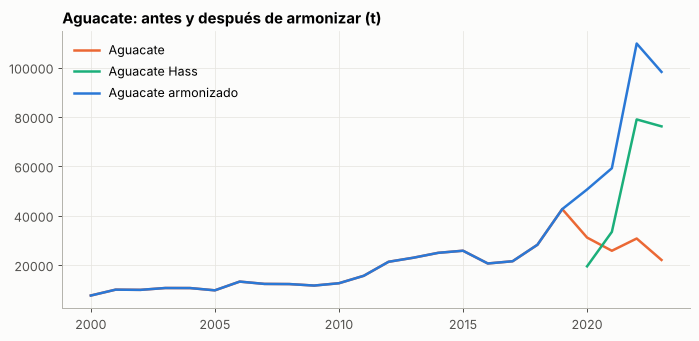

In [7]:
raw = pd.read_csv(next(RAW.glob("*permanentes*.csv")), dtype=str)
raw["anio"] = pd.to_numeric(raw["Año"].str.replace(",", "")); raw["t"] = pd.to_numeric(raw["Produccion_toneladas"].str.replace(",", ""))
antes = raw[raw.Cultivo.isin(["Aguacate", "Aguacate Hass"])].drop_duplicates().pivot_table(index="anio", columns="Cultivo", values="t", aggfunc="sum")
despues = d[d.producto == "Aguacate"].groupby("anio")["produccion_t"].sum()
ax = antes.plot(color=COLORES[1:3], title="Aguacate: antes y después de armonizar (t)")
despues.plot(ax=ax, color=COLORES[0], label="Aguacate armonizado"); ax.legend(); ax.set_xlabel("")
plt.show()

**Lectura.** Los conteos cuadran con la propuesta. Los 22 detallados se eligieron por **toneladas** 2019-2023; en el notebook 04 se compara con un ranking por **valor** (SIPSA) y en `docs/ML_C/decisiones_modelado.md` se explica por qué se mantuvo el de toneladas.